In [1]:
!pip install -q nflreadpy pyarrow fastapi uvicorn httpx pytest
from google.colab import drive
drive.mount('/content/drive')

import os
for d in ["app", "models", "data", "tests", "scripts"]:
    os.makedirs(f"/content/nfl-api/{d}", exist_ok=True)
%cd /content/nfl-api
!touch app/__init__.py tests/__init__.py
!cp /content/drive/MyDrive/wp_model.json models/
!ls -R

Mounted at /content/drive
/content/nfl-api
.:
app  data  models  scripts  tests

./app:
__init__.py

./data:

./models:
wp_model.json

./scripts:

./tests:
__init__.py


In [2]:
%%writefile scripts/make_replay_data.py
"""Build data/replay.parquet: plays for every 2023-2025 game + Super Bowl LI (2016)."""
import nflreadpy as nfl
import pandas as pd

COLS = ["game_id", "season", "week", "play_type", "home_team", "away_team", "qtr", "time", "desc",
        "posteam", "game_seconds_remaining", "yardline_100",
        "total_home_score", "total_away_score", "spread_line", "vegas_home_wp"]

parts = [nfl.load_pbp([s]).select(COLS).to_pandas() for s in [2023, 2024, 2025]]
sb51 = nfl.load_pbp([2016]).select(COLS).to_pandas()
parts.append(sb51[sb51["game_id"] == "2016_21_NE_ATL"])

plays = pd.concat(parts, ignore_index=True)
NEEDED = ["posteam", "spread_line", "yardline_100", "game_seconds_remaining",
          "total_home_score", "total_away_score", "qtr"]
plays = plays.dropna(subset=NEEDED)          # no blanks: the API cannot send NaN in JSON
# kickoffs / extra points: posteam is the KICKING team there, which fakes big swings
plays = plays[plays["play_type"].isin(["run", "pass", "punt", "field_goal", "qb_kneel", "qb_spike", "no_play"])]
plays.to_parquet("data/replay.parquet", index=False)
print(plays.shape, plays["game_id"].nunique(), "games")

Writing scripts/make_replay_data.py


In [3]:
!python scripts/make_replay_data.py

(124831, 16) 856 games


In [4]:
%%writefile app/model.py
"""Win-probability model: loads wp_model.json and turns a game state into P(home win)."""
import json
from pathlib import Path

import numpy as np

ROOT = Path(__file__).resolve().parent.parent
MODEL = json.loads((ROOT / "models" / "wp_model.json").read_text())
MU = np.array(MODEL["mu"])
SD = np.array(MODEL["sd"])
W = np.array(MODEL["w"])
B = MODEL["b"]


def make_features(home_lead, secs_left, home_has_ball, home_yards_to_score, spread):
    """Exactly the same 7 features, in the same order, as in training."""
    frac_left = min(max(secs_left / 3600, 0.0), 1.0)
    x = {
        "home_lead": home_lead,
        "time_left": secs_left,
        "home_has_ball": float(home_has_ball),
        "home_yards_to_score": home_yards_to_score,
        "lead_x_time": home_lead * (1 - frac_left),
        "spread": spread,
        "spread_x_time": spread * frac_left,
    }
    return np.array([x[f] for f in MODEL["features"]], dtype=float)


def win_probability(home_lead, secs_left, home_has_ball, home_yards_to_score, spread):
    x = (make_features(home_lead, secs_left, home_has_ball, home_yards_to_score, spread) - MU) / SD
    z = x @ W + B
    return float(1 / (1 + np.exp(-z)))

Writing app/model.py


In [5]:
%%writefile app/main.py
"""FastAPI app: live win probability for any game state, plus replay of a past game."""
from functools import lru_cache
from pathlib import Path

import pandas as pd
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field

from app.model import win_probability

app = FastAPI(title="NFL Win-Probability API")
DATA = Path(__file__).resolve().parent.parent / "data" / "replay.parquet"


class GameState(BaseModel):
    home_lead: int = Field(..., ge=-80, le=80, description="home score minus away score")
    secs_left: int = Field(..., ge=0, le=4500, description="game seconds remaining (3600 at kickoff)")
    home_has_ball: bool
    yardline_100: int = Field(..., ge=1, le=99, description="yards from the OFFENSE's goal line to score")
    spread: float = Field(0.0, ge=-30, le=30, description="pre-game spread, + means home favored")


@app.get("/health")
def health():
    return {"status": "ok"}


@app.post("/win-probability")
def predict(state: GameState):
    # convert to the home team's point of view, exactly like training
    home_yards = state.yardline_100 if state.home_has_ball else 100 - state.yardline_100
    p = win_probability(state.home_lead, state.secs_left, state.home_has_ball,
                        home_yards, state.spread)
    return {"home_win_prob": round(p, 4), "away_win_prob": round(1 - p, 4)}


@lru_cache
def load_plays():
    return pd.read_parquet(DATA)


@app.get("/games")
def list_games(season: int | None = None):
    plays = load_plays()
    if season is not None:
        plays = plays[plays["season"] == season]
    games = plays.drop_duplicates("game_id")[["game_id", "season", "week", "away_team", "home_team"]]
    return games.to_dict(orient="records")


@app.get("/replay/{game_id}")
def replay(game_id: str, top_swings: int = 5):
    plays = load_plays()
    g = plays[plays["game_id"] == game_id]
    if g.empty:
        raise HTTPException(status_code=404, detail=f"game {game_id} not found")

    rows = []
    for r in g.itertuples():
        has_ball = r.posteam == r.home_team
        home_yards = r.yardline_100 if has_ball else 100 - r.yardline_100
        lead = r.total_home_score - r.total_away_score
        p = win_probability(lead, r.game_seconds_remaining, has_ball, home_yards, r.spread_line)
        rows.append({"qtr": int(r.qtr), "time": r.time, "home_score": int(r.total_home_score),
                     "away_score": int(r.total_away_score), "home_win_prob": round(p, 4),
                     "nflverse_home_wp": None if pd.isna(r.vegas_home_wp) else round(float(r.vegas_home_wp), 4),
                     "desc": r.desc})

    # swing = how much this play moved the probability vs the previous play
    for i in range(len(rows)):
        prev = rows[i - 1]["home_win_prob"] if i > 0 else rows[0]["home_win_prob"]
        rows[i]["swing"] = round(rows[i]["home_win_prob"] - prev, 4)
    swings = sorted(rows, key=lambda r: abs(r["swing"]), reverse=True)[:top_swings]

    first = g.iloc[0]
    return {"game_id": game_id, "home_team": first.home_team, "away_team": first.away_team,
            "spread": float(first.spread_line), "n_plays": len(rows),
            "top_swings": swings, "plays": rows}

Writing app/main.py


In [9]:
%%writefile tests/test_api.py
from fastapi.testclient import TestClient

from app.main import app

client = TestClient(app)


def wp(**state):
    r = client.post("/win-probability", json=state)
    assert r.status_code == 200
    return r.json()["home_win_prob"]


def test_health():
    assert client.get("/health").json() == {"status": "ok"}


def test_probabilities_add_up():
    r = client.post("/win-probability",
                    json={"home_lead": 3, "secs_left": 1800, "home_has_ball": True, "yardline_100": 60}).json()
    assert abs(r["home_win_prob"] + r["away_win_prob"] - 1) < 1e-3


def test_late_lead_is_high():
    assert wp(home_lead=7, secs_left=120, home_has_ball=True, yardline_100=50) > 0.8


def test_bigger_lead_never_lowers_prob():
    probs = [wp(home_lead=l, secs_left=600, home_has_ball=False, yardline_100=60) for l in range(-21, 22)]
    assert all(b >= a for a, b in zip(probs, probs[1:]))


def test_favorite_beats_underdog_at_kickoff():
    fav = wp(home_lead=0, secs_left=3600, home_has_ball=False, yardline_100=75, spread=7)
    dog = wp(home_lead=0, secs_left=3600, home_has_ball=False, yardline_100=75, spread=-7)
    assert fav > 0.6 > 0.4 > dog


def test_bad_input_rejected():
    r = client.post("/win-probability",
                    json={"home_lead": 3, "secs_left": -5, "home_has_ball": True, "yardline_100": 60})
    assert r.status_code == 422


def test_replay_super_bowl_51():
    r = client.get("/replay/2016_21_NE_ATL").json()
    assert r["home_team"] == "ATL"
    lowest_for_ne = 1 - max(p["home_win_prob"] for p in r["plays"])
    assert lowest_for_ne < 0.05          # NE was nearly dead at 28-3...
    assert r["plays"][-1]["away_score"] > r["plays"][-1]["home_score"]   # ...and still won


def test_replay_unknown_game_404():
    assert client.get("/replay/1999_01_XXX_YYY").status_code == 404

Overwriting tests/test_api.py


In [10]:
!python -m pytest -q

........                                                                 [100%]
8 passed in 1.78s


In [11]:
!grep -c "def test_" tests/test_api.py
!python -m pytest -v

8
============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/nfl-api
plugins: langsmith-0.14.17, typeguard-4.6.0, anyio-4.16.0, platformdirs-4.14.3
collected 8 items                                                              

tests/test_api.py::test_health PASSED                                    [ 12%]
tests/test_api.py::test_probabilities_add_up PASSED                      [ 25%]
tests/test_api.py::test_late_lead_is_high PASSED                         [ 37%]
tests/test_api.py::test_bigger_lead_never_lowers_prob PASSED             [ 50%]
tests/test_api.py::test_favorite_beats_underdog_at_kickoff PASSED        [ 62%]
tests/test_api.py::test_bad_input_rejected PASSED                        [ 75%]
tests/test_api.py::test_replay_super_bowl_51 PASSED                      [ 87%]
tests/test_api.py::test_replay_unknown_game_404 PASSED            

In [12]:
!nohup uvicorn app.main:app --port 8000 > server.log 2>&1 &
!sleep 4
!cat server.log

In [13]:
!curl -s localhost:8000/health
print()
!curl -s -X POST localhost:8000/win-probability -H "Content-Type: application/json" -d '{"home_lead": 7, "secs_left": 120, "home_has_ball": true, "yardline_100": 50}'
print()
!curl -s -X POST localhost:8000/win-probability -H "Content-Type: application/json" -d '{"home_lead": 7, "secs_left": -5, "home_has_ball": true, "yardline_100": 50}'

{"status":"ok"}
{"home_win_prob":0.8744,"away_win_prob":0.1256}
{"detail":[{"type":"greater_than_equal","loc":["body","secs_left"],"msg":"Input should be greater than or equal to 0","input":-5,"ctx":{"ge":0}}]}

lowest NE win prob: 0.012

Top swings:
  Q4 01:00  NE 26-28 ATL  swing -0.36  (1:00) 28-J.White right guard for 1 yard, TOUCHDOWN.
  Q5 11:08  NE 34-28 ATL  swing -0.21  (11:08) 28-J.White right end for 2 yards, TOUCHDOWN. The Rep
  Q2 12:20  NE 0-6 ATL  swing +0.18  (12:20) (Shotgun) 24-D.Freeman left end for 5 yards, TOUCHDO
  Q2 08:55  NE 0-13 ATL  swing +0.14  (8:55) (Shotgun) 2-M.Ryan pass deep left to 81-A.Hooper for 
  Q4 00:57  NE 28-28 ATL  swing -0.12  TWO-POINT CONVERSION ATTEMPT. 12-T.Brady pass to 80-D.Amendo


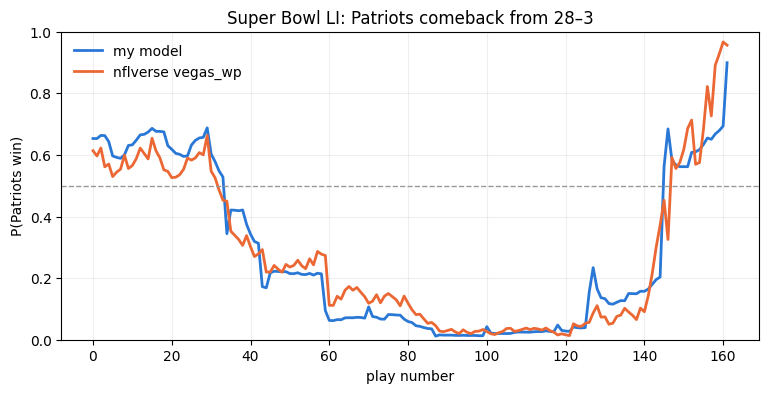

In [14]:
import requests
import matplotlib.pyplot as plt

r = requests.get("http://localhost:8000/replay/2016_21_NE_ATL").json()
ne_prob = [1 - p["home_win_prob"] for p in r["plays"]]          # ATL is home, so NE = 1 - p
nfl_ne  = [None if p["nflverse_home_wp"] is None else 1 - p["nflverse_home_wp"] for p in r["plays"]]

print("lowest NE win prob:", round(min(ne_prob), 3))
print("\nTop swings:")
for s in r["top_swings"]:
    print(f"  Q{s['qtr']} {s['time']}  NE {s['away_score']}-{s['home_score']} ATL  swing {s['swing']:+.2f}  {s['desc'][:60]}")

plt.figure(figsize=(9, 4))
plt.plot(ne_prob, color="#2a78d6", lw=2, label="my model")
plt.plot(nfl_ne, color="#eb6834", lw=2, label="nflverse vegas_wp")
plt.axhline(0.5, color="#999999", lw=1, ls="--")
plt.ylim(0, 1); plt.ylabel("P(Patriots win)"); plt.xlabel("play number")
plt.title("Super Bowl LI: Patriots comeback from 28–3")
plt.legend(frameon=False); plt.grid(alpha=0.2)
plt.show()

In [15]:
%%writefile requirements.txt
fastapi
uvicorn[standard]
pandas
pyarrow
numpy
pytest
httpx

Writing requirements.txt


In [16]:
%%writefile Dockerfile
FROM python:3.11-slim
WORKDIR /code
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY app/ app/
COPY models/ models/
COPY data/ data/
EXPOSE 7860
CMD ["uvicorn", "app.main:app", "--host", "0.0.0.0", "--port", "7860"]

Writing Dockerfile


In [17]:
import os
os.makedirs(".github/workflows", exist_ok=True)

In [18]:
%%writefile .github/workflows/tests.yml
name: tests
on: [push, pull_request]
jobs:
  test:
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: "3.11"
      - run: pip install -r requirements.txt
      - run: pytest -q

Writing .github/workflows/tests.yml


In [19]:
!pkill -f "uvicorn app.main"
!rm -f server.log
!rm -rf .pytest_cache app/__pycache__ tests/__pycache__
!cp -r /content/nfl-api /content/drive/MyDrive/
!cd /content && zip -rq nfl-api.zip nfl-api
from google.colab import files
files.download("/content/nfl-api.zip")
!find . -type f | sort

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

./app/__init__.py
./app/main.py
./app/model.py
./data/replay.parquet
./Dockerfile
./.github/workflows/tests.yml
./models/wp_model.json
./requirements.txt
./scripts/make_replay_data.py
./tests/__init__.py
./tests/test_api.py
